In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN

dataset = pd.read_csv("../data/raw/dataset-6ab989b678d90892980305.csv")


In [3]:
# removing one missing values (discoved in EDA)

dataset.dropna(subset=["CREDIT_LIMIT"] , inplace=True)
dataset.loc[dataset["CREDIT_LIMIT"].isna()]


# df clean should be here : 

df_clean = dataset.copy()

df_clean 


,CUST_ID,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
0,C10001,40.900749,95.40,0.00,95.40,0.000000,1000.0,201.802084
1,C10002,3202.467416,0.00,0.00,0.00,6442.945483,7000.0,4103.032597
2,C10003,2495.148862,773.17,773.17,0.00,0.000000,7500.0,622.066742
3,C10004,1666.670542,1499.00,1499.00,0.00,205.788017,7500.0,0.000000
4,C10005,817.714335,16.00,16.00,0.00,0.000000,1200.0,678.334763
...,...,...,...,...,...,...,...,...
8945,C19186,28.493517,291.12,0.00,291.12,0.000000,1000.0,325.594462
8946,C19187,19.183215,300.00,0.00,300.00,0.000000,1000.0,275.861322
8947,C19188,23.398673,144.40,0.00,144.40,0.000000,1000.0,81.270775
8948,C19189,13.457564,0.00,0.00,0.00,36.558778,500.0,52.549959


In [4]:
# outliers transformation wiht log1p :  
df_prepare_clustering = dataset.copy()

columns = df_prepare_clustering.drop(columns="CUST_ID").columns

for column in columns : 
    df_prepare_clustering[column] = np.log1p(df_prepare_clustering[column])
df_prepare_clustering



df_prepare_clustering


,CUST_ID,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
0,C10001,3.735304,4.568506,0.000000,4.568506,0.000000,6.908755,5.312231
1,C10002,8.071989,0.000000,0.000000,0.000000,8.770896,8.853808,8.319725
2,C10003,7.822504,6.651791,6.651791,0.000000,0.000000,8.922792,6.434654
3,C10004,7.419183,7.313220,7.313220,0.000000,5.331694,8.922792,0.000000
4,C10005,6.707735,2.833213,2.833213,0.000000,0.000000,7.090910,6.521114
...,...,...,...,...,...,...,...,...
8945,C19186,3.384170,5.677165,0.000000,5.677165,0.000000,6.908755,5.788719
8946,C19187,3.004851,5.707110,0.000000,5.707110,0.000000,6.908755,5.623517
8947,C19188,3.194529,4.979489,0.000000,4.979489,0.000000,6.908755,4.410016
8948,C19189,2.671218,0.000000,0.000000,0.000000,3.625907,6.216606,3.980615


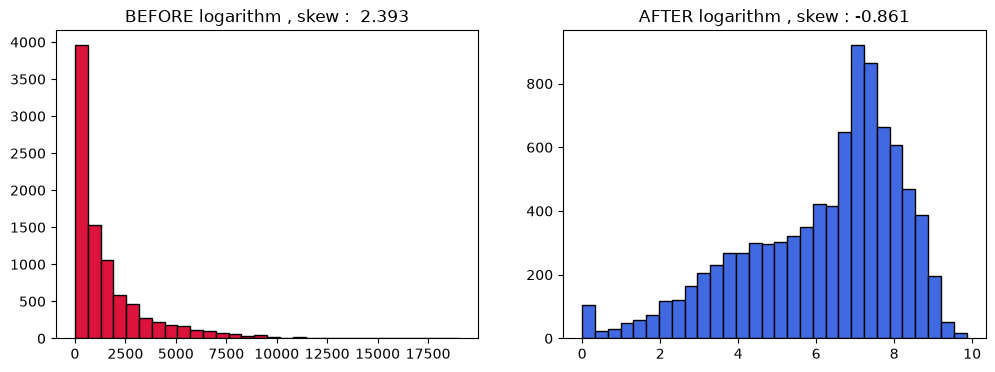

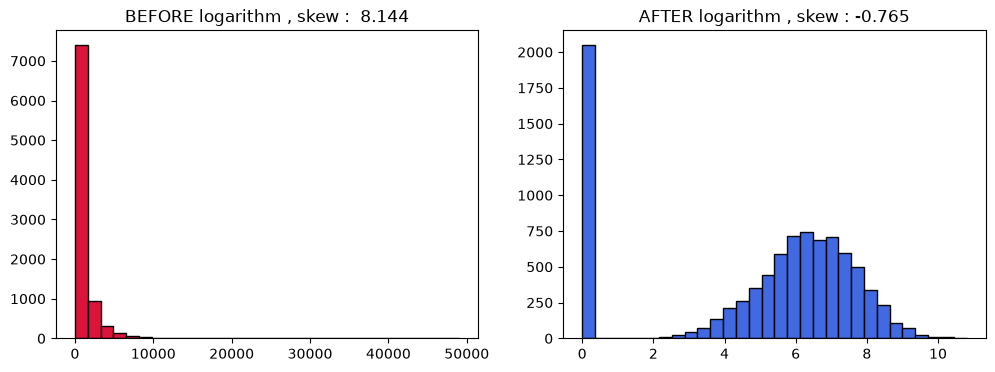

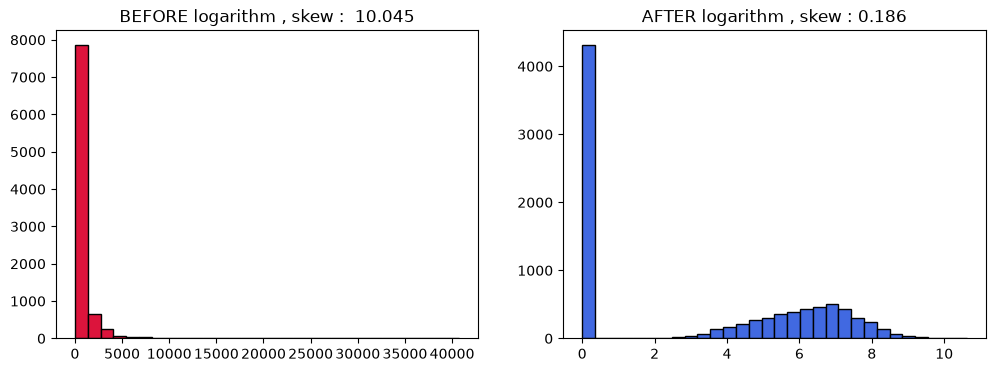

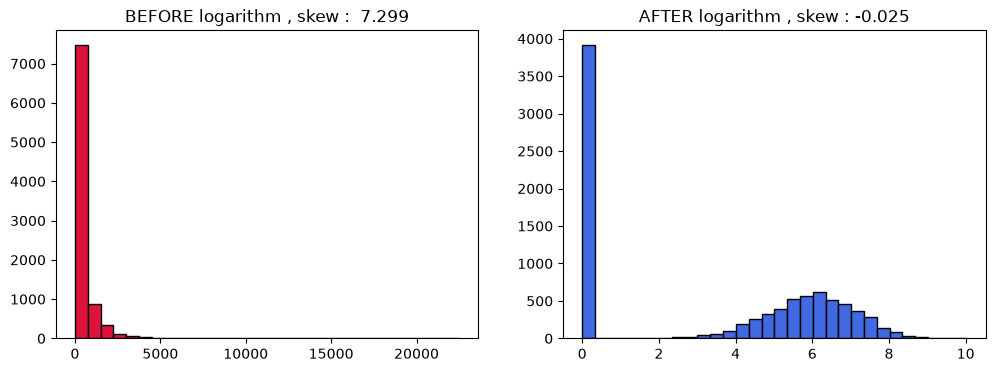

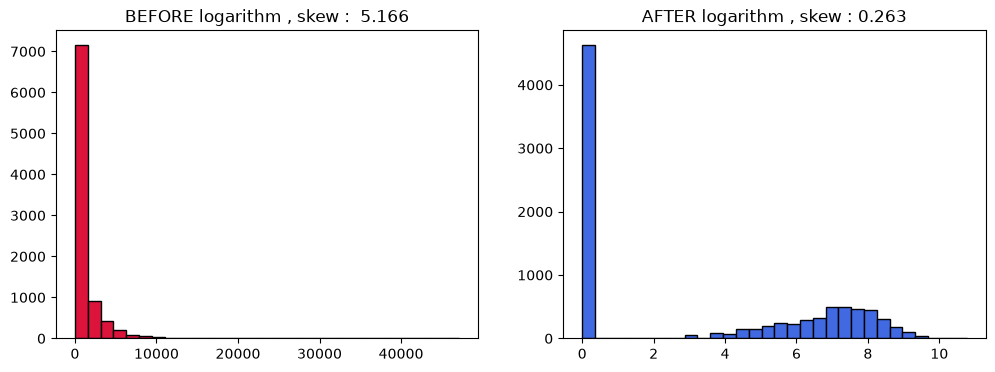

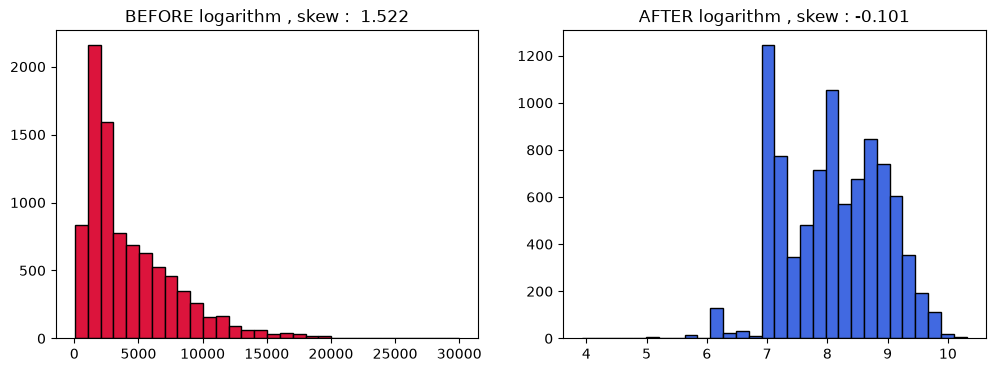

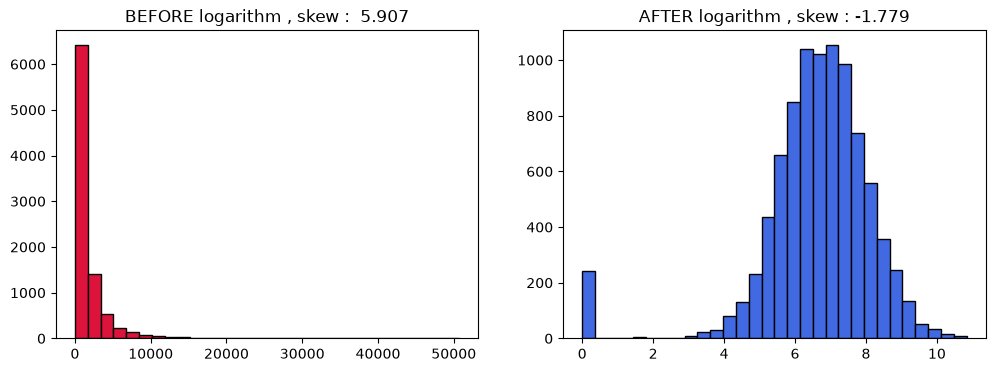

In [5]:
# making visualizing before and after logarithm :  

numeric_columns = df_prepare_clustering.drop(columns="CUST_ID").columns


for col in numeric_columns :
    
    skew_before = dataset[col].skew()
    skew_after = df_prepare_clustering[col].skew()
      
     
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    
    dataset[col].hist(ax=axes[0],  bins=30, color='crimson', edgecolor='black', grid=False)
    axes[0].set_title(f"BEFORE logarithm , skew :  {skew_before.round(3)}")
    df_prepare_clustering[col].hist(ax=axes[1], bins=30, color='royalblue', edgecolor='black', grid=False)
    axes[1].set_title(f"AFTER logarithm , skew : {skew_after.round(3)}")

In [6]:
# table of the above visualization :  

table = []

for col in numeric_columns : 
    
    skew_before = dataset[col].skew()
    skew_after = df_prepare_clustering[col].skew()
    
    
    table.append({
        "column" : col, 
        "Skewness Before" : skew_before, 
        "Skewness After" : skew_after, 
        "Objective Improvement" : "Yes" if abs(skew_after) < abs(skew_before) else "No"
    })
    
    
table_df = pd.DataFrame(table)

table_df
    

,column,Skewness Before,Skewness After,Objective Improvement
0,BALANCE,2.393270,-0.861421,Yes
1,PURCHASES,8.143969,-0.764844,Yes
2,ONEOFF_PURCHASES,10.044622,0.185650,Yes
3,INSTALLMENTS_PURCHASES,7.298823,-0.025206,Yes
4,CASH_ADVANCE,5.166323,0.262755,Yes
5,CREDIT_LIMIT,1.522464,-0.101438,Yes
6,PAYMENTS,5.907465,-1.779084,Yes


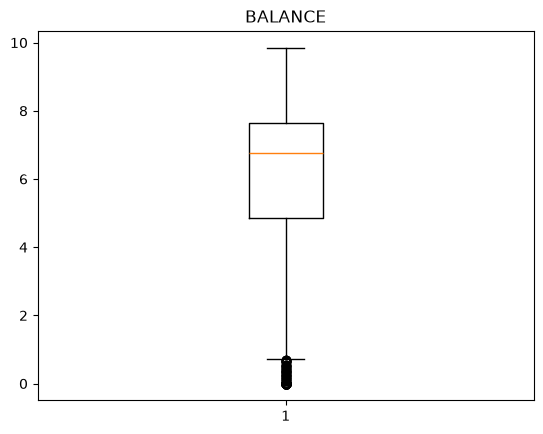

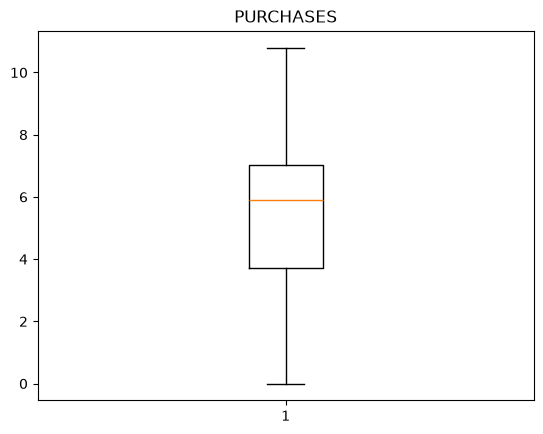

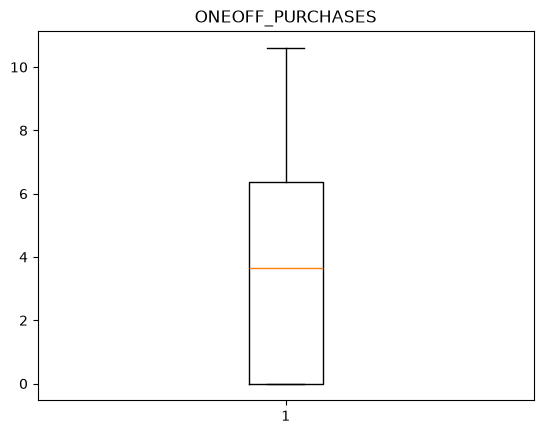

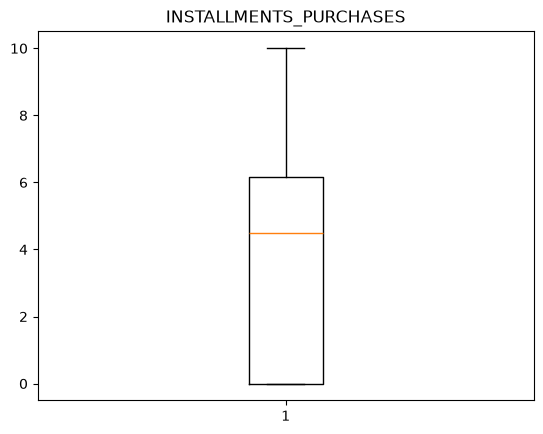

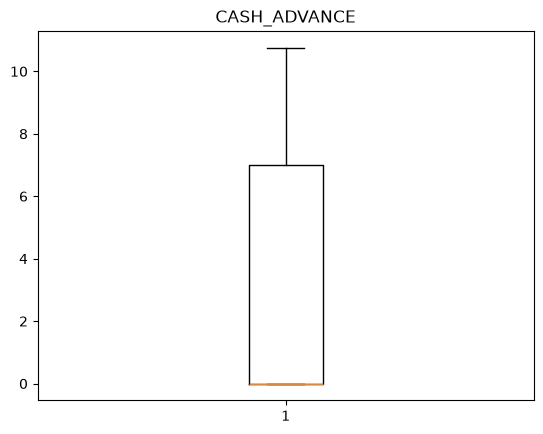

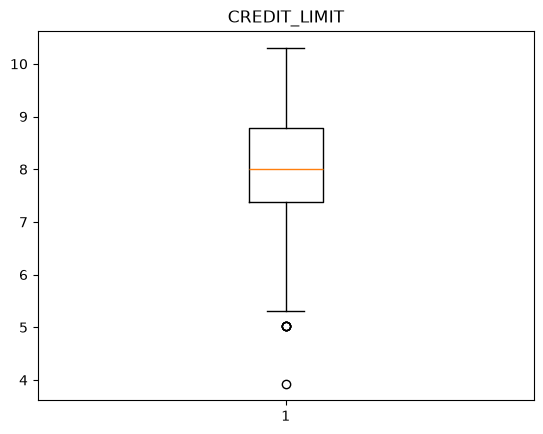

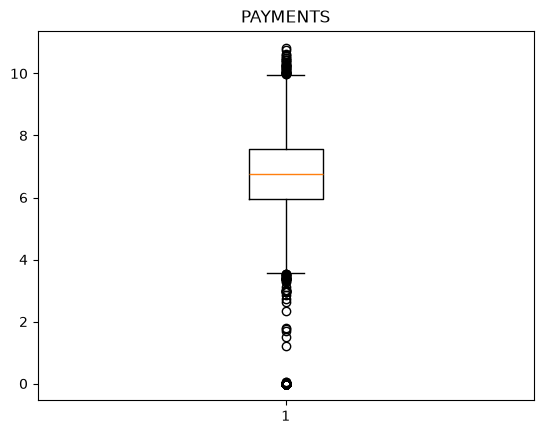

In [7]:
# box plot to see if we still have the same outliers : 

columns = df_prepare_clustering.select_dtypes(include="number").columns

for column in columns : 
    
    plt.boxplot(df_prepare_clustering[column])
    plt.title(f"{column}")
    plt.show()
    
    
    


In [8]:
columns = df_prepare_clustering.select_dtypes(include="number").columns

result = {}
for column in columns : 
    
    Q1 = df_prepare_clustering[column].quantile(0.25)
    
    Q3 = df_prepare_clustering[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    result[column] = len(df_prepare_clustering[
        (df_prepare_clustering[column] < lower_bound) |
        (df_prepare_clustering[column] > upper_bound)
    ])


result 

# we can see that the number of outliers has been decreassed alot when doing log transformation . 

{'BALANCE': 132,
 'PURCHASES': 0,
 'ONEOFF_PURCHASES': 0,
 'INSTALLMENTS_PURCHASES': 0,
 'CASH_ADVANCE': 0,
 'CREDIT_LIMIT': 6,
 'PAYMENTS': 317}

In [9]:
# applying StandardScaler : 

scaler = StandardScaler()

scaled_data = scaler.fit_transform(df_prepare_clustering.drop(columns="CUST_ID"))

scaled_df = pd.DataFrame(scaled_data , columns=df_prepare_clustering.drop(columns="CUST_ID").columns)

scaled_df.insert(0 , "CUST_ID", df_prepare_clustering["CUST_ID"].values) 

df_prepare_clustering= scaled_df

df_prepare_clustering

,CUST_ID,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
0,C10001,-1.205498,-0.113732,-0.987198,0.394362,-0.930636,-1.447095,-0.825080
1,C10002,0.948821,-1.680213,-0.987198,-1.087586,1.528788,0.925997,1.065109
2,C10003,0.824885,0.600600,1.061910,-1.087586,-0.930636,1.010161,-0.119646
3,C10004,0.624529,0.827395,1.265665,-1.087586,0.564410,1.010161,-4.163779
4,C10005,0.271106,-0.708741,-0.114417,-1.087586,-0.930636,-1.224854,-0.065306
...,...,...,...,...,...,...,...,...
8944,C19186,-1.379929,0.266413,-0.987198,0.753993,-0.930636,-1.447095,-0.525611
8945,C19187,-1.568362,0.276681,-0.987198,0.763707,-0.930636,-1.447095,-0.629439
8946,C19188,-1.474137,0.027189,-0.987198,0.527678,-0.930636,-1.447095,-1.392116
8947,C19189,-1.734100,-1.680213,-0.987198,-1.087586,0.086095,-2.291561,-1.661991


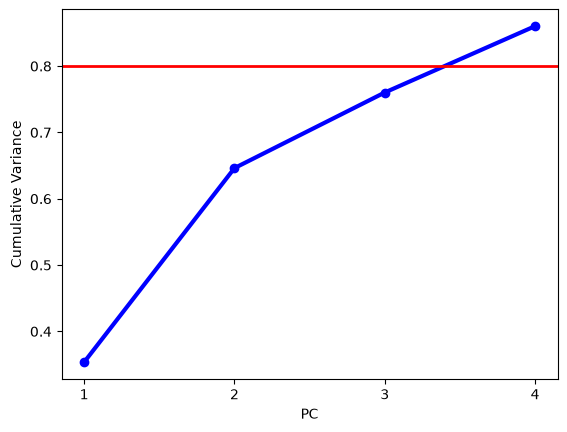

array([0.35362368, 0.64620914, 0.76017895, 0.86023261])

In [10]:
# implementing PCA :  Feature 2 . 

pca = PCA(n_components=4)

pca.fit(df_prepare_clustering.drop(columns="CUST_ID"))

"""# calculating the cumulative variance so we can use it to see how many PCAs we should keep . 
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
 
# we will define here the number of the number of components we should put as a param to PCA() : we found 4 :
components_number = np.argmax(cumulative_variance >= 0.8) + 1
"""


pc_values = np.arange(pca.n_components_) + 1


cumulative_variance = np.cumsum(pca.explained_variance_ratio_) 

plt.plot(pc_values , cumulative_variance , 'o-', linewidth=3 , color="blue")
plt.axhline(y=0.80, color='red', linestyle='-', linewidth=2, label="80% Threshold")
plt.xticks(pc_values)
plt.title("")
plt.xlabel("PC")
plt.ylabel("Cumulative Variance")
plt.show()

cumulative_variance

    

In [11]:
# implementing KMeans ( i should know the exact number of n_components and also k in kmeans):

results = []

for n_component in range(2, 6) : 
    # i will apply PCA here : 
    
    pca = PCA(n_components=n_component)
    
    X_pca = pca.fit_transform(df_prepare_clustering.drop(columns="CUST_ID"))
    
    
    
    for k in range(2, 8) : 
        # i will apply Kmeans here and save the result . 
        
        kmeans = KMeans(n_clusters=k)
        
        labels = kmeans.fit_predict(X_pca)
        
        inertia = kmeans.inertia_
         
        silhouette = silhouette_score(X_pca , labels)
        results.append({
            "n_components" : n_component, 
            "k" : k , 
            "silhouette" : silhouette , 
            "inertia" : inertia
        })



results_df = pd.DataFrame(results)

results_df


,n_components,k,silhouette,inertia
0,2,2,0.431301,23542.506783
1,2,3,0.448851,13244.772703
2,2,4,0.423217,10416.107828
3,2,5,0.411270,8251.102013
4,2,6,0.393785,6689.680677
5,2,7,0.397686,5635.361884
6,3,2,0.367717,30681.259354
7,3,3,0.383388,20206.779473
8,3,4,0.388836,16447.973056
9,3,5,0.386774,13909.886463


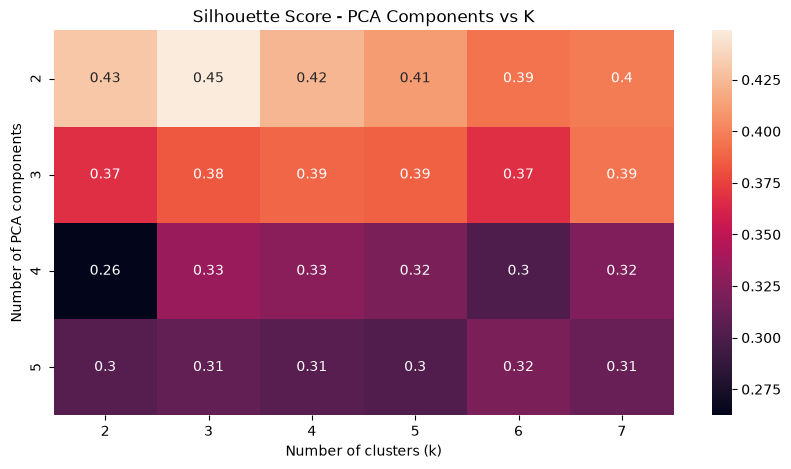

In [12]:

results_df


heatmap_data = results_df.pivot(
    index="n_components", 
    columns="k",
    values="silhouette"
)
heatmap_data


plt.figure(figsize=(10, 5))

sns.heatmap(
    heatmap_data , 
    annot=True,
    fmt=".2"
)

plt.title("Silhouette Score - PCA Components vs K")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Number of PCA components")

plt.show()


Text(0.5, 1.0, 'Elbow curve')

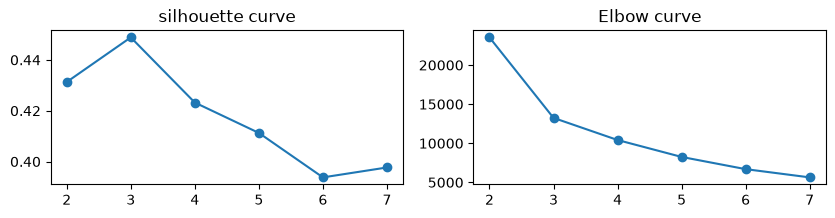

In [13]:
# silhouette curve 
pca_2_results = results_df[
    results_df["n_components"] == 2
]

pca_2_results

fig , axes = plt.subplots(1, 2, figsize=(10, 2))
axes[0].plot(
    pca_2_results["k"],
    pca_2_results["silhouette"], 
    'o-'
    )
axes[0].set_title("silhouette curve")

axes[1].plot(
    pca_2_results["k"], 
    pca_2_results["inertia"],
    'o-'
)

axes[1].set_title("Elbow curve")



In [14]:
# after ensuring that k = 3 , and also the PCs are two . now we can create our PCA and Kmeans . 

pca = PCA(n_components=2) 

x_pca = pca.fit_transform(df_prepare_clustering.drop(columns="CUST_ID"))


kmeans = KMeans(
    n_clusters=3,
    random_state=42
)



labels = kmeans.fit_predict(x_pca)

centroids = kmeans.cluster_centers_

column_name = "cluster_kmeans"

best_kmeans_silhouette = silhouette_score(x_pca , labels)

best_kmeans_silhouette


0.4487397411479185

In [15]:
# adding clutering labels to  df_clean : 

df_clean["cluster_kmeans"] = labels

df_clean

,CUST_ID,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,cluster_kmeans
0,C10001,40.900749,95.40,0.00,95.40,0.000000,1000.0,201.802084,2
1,C10002,3202.467416,0.00,0.00,0.00,6442.945483,7000.0,4103.032597,0
2,C10003,2495.148862,773.17,773.17,0.00,0.000000,7500.0,622.066742,1
3,C10004,1666.670542,1499.00,1499.00,0.00,205.788017,7500.0,0.000000,2
4,C10005,817.714335,16.00,16.00,0.00,0.000000,1200.0,678.334763,2
...,...,...,...,...,...,...,...,...,...
8945,C19186,28.493517,291.12,0.00,291.12,0.000000,1000.0,325.594462,2
8946,C19187,19.183215,300.00,0.00,300.00,0.000000,1000.0,275.861322,2
8947,C19188,23.398673,144.40,0.00,144.40,0.000000,1000.0,81.270775,2
8948,C19189,13.457564,0.00,0.00,0.00,36.558778,500.0,52.549959,2


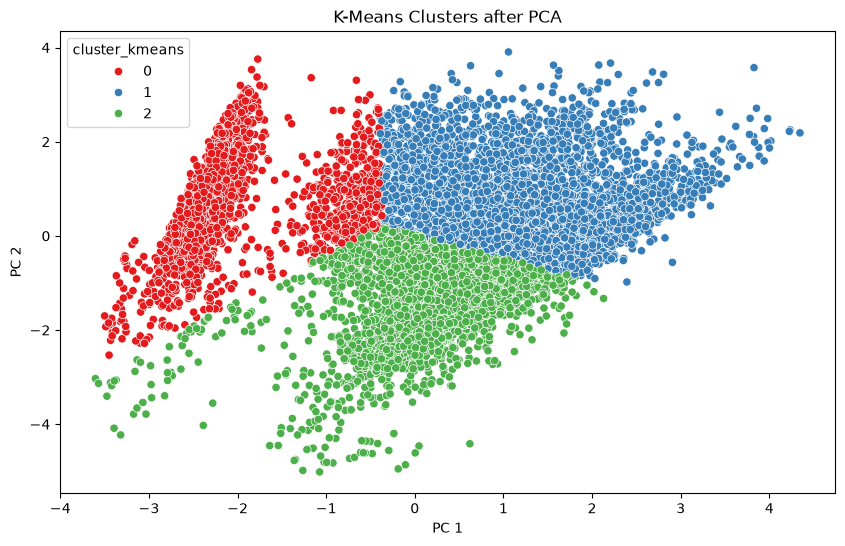

,PC1,PC2,cluster_kmeans
0,-0.457236,-2.343430,2
1,-2.100598,2.188513,0
2,0.829442,0.714435,1
3,-0.334924,-0.589284,2
4,-0.940884,-0.636421,2
...,...,...,...
8944,0.008679,-2.373310,2
8945,0.002344,-2.534881,2
8946,-0.425151,-2.793521,2
8947,-2.793256,-2.638398,2


In [16]:
# visualize the clusters : 

pca_df = pd.DataFrame(x_pca, columns=["PC1", "PC2"] )


pca_df["cluster_kmeans"] = labels


pca_df

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="cluster_kmeans",
    palette="Set1"
)

plt.title("K-Means Clusters after PCA")
plt.xlabel("PC 1")
plt.ylabel("PC 2")

plt.show()
pca_df



In [17]:
# DBSCAN : Feature 3 .

# i will use x_pca in fitting and predicting and from the var above which is : x_pca
eps_values = np.arange(0.5, 2.5, 0.5)
min_samples_values = np.arange(4, 9)
result_of_DBSCAN = []
for n in range(2, 6) :
    pca = PCA(n_components=n) 
  
    x_pca = pca.fit_transform(df_prepare_clustering.drop(columns="CUST_ID"))
    
    for eps in eps_values : 
        
        
        for min_sample in min_samples_values : 
           
            dbscan = DBSCAN(
                eps=eps, 
                min_samples=min_sample
            )
            
            lables  = dbscan.fit_predict(x_pca)
            
            n_clusters = len(set(lables)) - (1 if -1 in lables else 0)
            
            n_noise = np.sum(lables == -1)
            
            mask = lables != -1
            
            
            if n_clusters >= 2 : 
                silhouette = silhouette_score(
                            x_pca[mask], 
                            lables[mask]          
                )
                
            else : 
                silhouette = np.nan
            
            result_of_DBSCAN.append({
                "n_components": n, 
                "min_samples" : min_sample, 
                "eps" : eps, 
                "n_clusters" : n_clusters, 
                "n_noise" : n_noise, 
                "silhouette" : silhouette 
            })
            
            


result_of_DBSCAN     
        
        
        
 
    


[{'n_components': 2,
  'min_samples': np.int64(4),
  'eps': np.float64(0.5),
  'n_clusters': 1,
  'n_noise': np.int64(5),
  'silhouette': nan},
 {'n_components': 2,
  'min_samples': np.int64(5),
  'eps': np.float64(0.5),
  'n_clusters': 1,
  'n_noise': np.int64(5),
  'silhouette': nan},
 {'n_components': 2,
  'min_samples': np.int64(6),
  'eps': np.float64(0.5),
  'n_clusters': 1,
  'n_noise': np.int64(6),
  'silhouette': nan},
 {'n_components': 2,
  'min_samples': np.int64(7),
  'eps': np.float64(0.5),
  'n_clusters': 1,
  'n_noise': np.int64(6),
  'silhouette': nan},
 {'n_components': 2,
  'min_samples': np.int64(8),
  'eps': np.float64(0.5),
  'n_clusters': 1,
  'n_noise': np.int64(6),
  'silhouette': nan},
 {'n_components': 2,
  'min_samples': np.int64(4),
  'eps': np.float64(1.0),
  'n_clusters': 1,
  'n_noise': np.int64(0),
  'silhouette': nan},
 {'n_components': 2,
  'min_samples': np.int64(5),
  'eps': np.float64(1.0),
  'n_clusters': 1,
  'n_noise': np.int64(0),
  'silhouette'

In [18]:
# save the output from the last bloc : 
dbscan_df = pd.DataFrame(result_of_DBSCAN) 
dbscan_df.to_csv('../data/processed/dbscan_df.csv')

dbscan_df =dbscan_df.dropna()



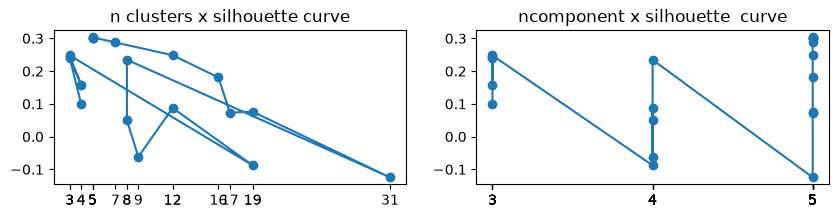

In [19]:
# visualization :  





fig , axes = plt.subplots(1, 2, figsize=(10, 2))
axes[0].plot(
    dbscan_df["n_clusters"],
   dbscan_df["silhouette"], 
    'o-'
    )
axes[0].set_title("n clusters x silhouette curve")
axes[0].set_xticks(dbscan_df["n_clusters"])
axes[1].plot(
    dbscan_df["n_components"], 
    dbscan_df["silhouette"],
    'o-'
)

axes[1].set_title("ncomponent x silhouette  curve")
axes[1].set_xticks(dbscan_df["n_components"])

plt.show()

In [20]:
# CALCULATING NOISE PERCENTAGE : 
dbscan_df




,n_components,min_samples,eps,n_clusters,n_noise,silhouette
20,3,4,0.5,4,35,0.099740
21,3,5,0.5,3,47,0.239462
22,3,6,0.5,4,54,0.158993
23,3,7,0.5,3,61,0.243512
24,3,8,0.5,3,77,0.247995
40,4,4,0.5,19,262,-0.087749
41,4,5,0.5,12,348,0.087459
42,4,6,0.5,9,422,-0.061847
43,4,7,0.5,8,485,0.049730
44,4,8,0.5,8,530,0.234683


<Axes: xlabel='eps', ylabel='min_samples'>

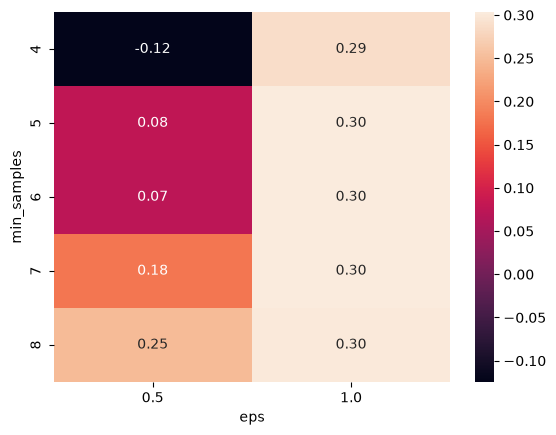

In [21]:
# creating heatmap for eps and min_samples with the silhouette as values . 
# i see that are three high values in silhoute when eps = 1 but min_samples = 8 , 7 , 6 . so i will see when n_clusters = 5 in the next bloc of code . 
pca_5_df = dbscan_df[
    dbscan_df["n_components"] == 5
]
heatmap_df = pca_5_df.pivot(
    index="min_samples", 
    columns="eps", 
    values="silhouette"   
)





sns.heatmap(
    heatmap_df, 
    annot=True, 
    fmt=".2f"  
)

<Axes: xlabel='eps', ylabel='min_samples'>

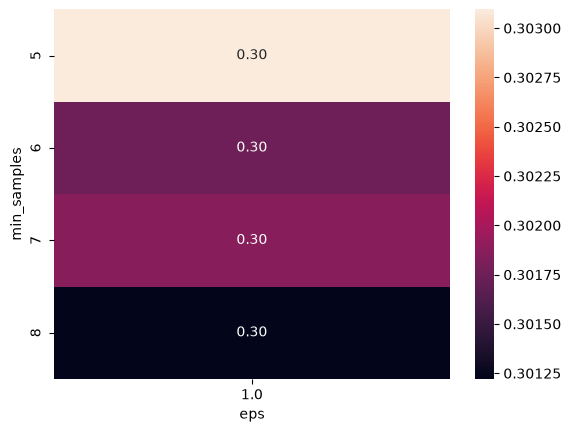

In [22]:
# ican see that the best eps is 1 in eps but still the min_samples in a range so i will use the n_noise in the next bloc of code . 
cluster_5_df = dbscan_df[
    dbscan_df["n_clusters"] == 5
]
heatmap_df = cluster_5_df.pivot(
    index="min_samples", 
    columns="eps", 
    values="silhouette"   
)





sns.heatmap(
    heatmap_df, 
    annot=True, 
    fmt=".2f"  
)



In [23]:
# so i can see that the best hyperparams for db scan are min_samples = 5 and eps = 1.0 and n_clusters = 5 and n_component = 5 . 

dbscan_df[
    (dbscan_df["min_samples"] == 5) & (dbscan_df["eps"] == 1.0) & (dbscan_df["n_clusters"] == 5) & (dbscan_df["n_components"] == 5)
]


best_dbscan_silhouette = dbscan_df[
    (dbscan_df["min_samples"] == 5) & (dbscan_df["eps"] == 1.0) & (dbscan_df["n_clusters"] == 5) & (dbscan_df["n_components"] == 5)
]["silhouette"]

best_dbscan_silhouette = best_dbscan_silhouette.iloc[0]

best_dbscan_silhouette

np.float64(0.3030952997480441)

In [24]:
# i will create now new pca and dbscan with their hyperparams : 

dbscan_pca = PCA(n_components=5) 

x_dbscan_pca = dbscan_pca.fit_transform(df_prepare_clustering.drop(columns="CUST_ID"))


dbscan = DBSCAN(
    eps=1.0,
    min_samples=5,    
)
labels = dbscan.fit_predict(x_dbscan_pca)

df_clean["cluster_dbscan"] = labels
"""
pca_df = pd.DataFrame(x_pca, columns=["PC1", "PC2"] )


pca_df["cluster_kmeans"] = labels


pca_df

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="cluster_kmeans",
    palette="Set1"
)

plt.title("K-Means Clusters after PCA")
plt.xlabel("PC 1")
plt.ylabel("PC 2")

plt.show()
pca_df


"""


df_clean

result = {}

print(len(labels))
for x in labels : 
    
    result[f"{x}"] = np.sum(labels == x)
    
result

8949


{'0': np.int64(8682),
 '1': np.int64(68),
 '-1': np.int64(62),
 '2': np.int64(69),
 '3': np.int64(54),
 '4': np.int64(14)}

In [25]:
# create the new colum for 1 0 values if it is a noise or no :  

df_clean["is_atypical_dbscan"] = df_clean["cluster_dbscan"] == -1


noise_percentage_dbscan = df_clean["is_atypical_dbscan"].mean() * 100


noise_percentage_dbscan

np.float64(0.6928148396468878)

In [26]:
# from the output of this code below i can see that the cluster number 0 include almost 97.7% of our dataset (in dbscan ) and 
dbscan_balance = df_clean.loc[df_clean["cluster_dbscan"] != -1 , "cluster_dbscan"].value_counts(normalize=True).mul(100)

kmeans_balance = df_clean["cluster_kmeans"].value_counts(normalize=True).mul(100)


kmeans_balance

cluster_kmeans
1    37.914851
2    34.953626
0    27.131523
Name: proportion, dtype: float64

In [27]:
# i will see the best one (dbscan or kmeans)

print(f"best_kmeans_silhouette : {best_kmeans_silhouette}")
print(f"best_dbscan_silhouette : {best_dbscan_silhouette}")


# so i can see that k means is good so i will choose it in this case because its silhoutte is higher than the dbscan . 



# so the cluster final column will have the values of cluster_kmeans . 

df_clean["cluster_final"] = df_clean["cluster_kmeans"]

df_clean

best_kmeans_silhouette : 0.4487397411479185
best_dbscan_silhouette : 0.3030952997480441


,CUST_ID,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,cluster_kmeans,cluster_dbscan,is_atypical_dbscan,cluster_final
0,C10001,40.900749,95.40,0.00,95.40,0.000000,1000.0,201.802084,2,0,False,2
1,C10002,3202.467416,0.00,0.00,0.00,6442.945483,7000.0,4103.032597,0,0,False,0
2,C10003,2495.148862,773.17,773.17,0.00,0.000000,7500.0,622.066742,1,0,False,1
3,C10004,1666.670542,1499.00,1499.00,0.00,205.788017,7500.0,0.000000,2,1,False,2
4,C10005,817.714335,16.00,16.00,0.00,0.000000,1200.0,678.334763,2,0,False,2
...,...,...,...,...,...,...,...,...,...,...,...,...
8945,C19186,28.493517,291.12,0.00,291.12,0.000000,1000.0,325.594462,2,0,False,2
8946,C19187,19.183215,300.00,0.00,300.00,0.000000,1000.0,275.861322,2,0,False,2
8947,C19188,23.398673,144.40,0.00,144.40,0.000000,1000.0,81.270775,2,0,False,2
8948,C19189,13.457564,0.00,0.00,0.00,36.558778,500.0,52.549959,2,0,False,2


<Axes: xlabel='PC1', ylabel='PC2'>

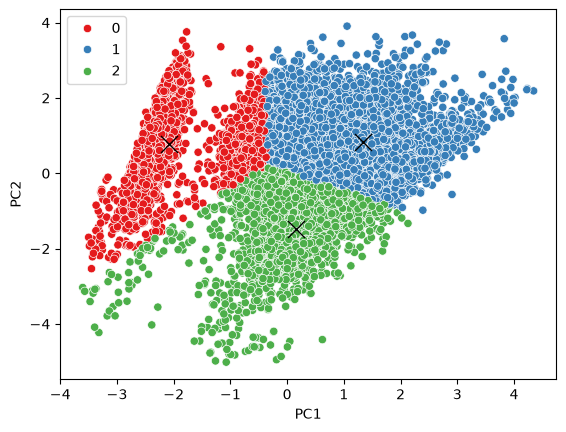

In [28]:
# visualizing the clusters and their centroids . 

# cluster_kmeans
pca_df

centroids = pd.DataFrame(centroids)
sns.scatterplot(data=pca_df , x="PC1", y="PC2", hue="cluster_kmeans", palette="Set1")
sns.scatterplot(data=centroids , x=0, y=1 , s=150, marker="x",color="black")


In [29]:
"""
Calculate the cluster means (standardised view): for each cluster, calculate the mean of each
variable on the transformed/standardised dataset. This makes it easy to compare the clusters
"""

"cluster_final"


def calculate_cluster_mean(dataset) : 
   
    return dataset.groupby("cluster_final").agg(
    balance_avg  = ('BALANCE', 'mean'),
    purchase_avg = ("PURCHASES", 'mean'), 
    oneoff_purchase = ("ONEOFF_PURCHASES" , 'mean'),
    INSTALLMENTS_PURCHASES = ("INSTALLMENTS_PURCHASES" , 'mean'),
    CASH_ADVANCE = ("CASH_ADVANCE" , 'mean'),
    CREDIT_LIMIT = ("CREDIT_LIMIT" , 'mean'),
    PAYMENTS = ("PAYMENTS" , 'mean')
    )



df_prepare_clustering

x_scaled = df_prepare_clustering.copy()

x_scaled["cluster_final"] = df_clean["cluster_final"]

x_scaled

calculate_cluster_mean(x_scaled)

calculate_cluster_mean(df_clean)



,balance_avg,purchase_avg,oneoff_purchase,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
cluster_final,,,,,,,
0,2176.510572,23.804876,19.040836,4.814152,2008.694406,3982.504618,1630.551945
1,2263.951257,2198.832193,1411.376935,787.687250,1095.701917,6525.855073,2888.626501
2,331.162731,466.831007,149.386630,318.012730,53.031643,2688.325018,559.954794


In [30]:
# from the output of the last output , i can see the following things : 
"""
for cluster 0 : I see that they pay with cash more and they have high balance . 
for cluster 1 : I see that they pay with card more and they have high balance too and also credit limit and payments . 
for cluster 2 : they have low balance and low spending money on cash advance .   and purshases 

"""


'\nfor cluster 0 : I see that they pay with cash more and they have high balance . \nfor cluster 1 : I see that they pay with card more and they have high balance too and also credit limit and payments . \nfor cluster 2 : they have low balance and low spending money on cash advance .   and purshases \n\n'

In [31]:
# assign each cluster a name : 
clusters_titles = {
    0: "Cash-Advance", 
    1: "High-Value",
    2: "Low-Activity"
}

df_clean["target"] = df_clean["cluster_final"].map(clusters_titles)


df_clean

,CUST_ID,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,cluster_kmeans,cluster_dbscan,is_atypical_dbscan,cluster_final,target
0,C10001,40.900749,95.40,0.00,95.40,0.000000,1000.0,201.802084,2,0,False,2,Low-Activity
1,C10002,3202.467416,0.00,0.00,0.00,6442.945483,7000.0,4103.032597,0,0,False,0,Cash-Advance
2,C10003,2495.148862,773.17,773.17,0.00,0.000000,7500.0,622.066742,1,0,False,1,High-Value
3,C10004,1666.670542,1499.00,1499.00,0.00,205.788017,7500.0,0.000000,2,1,False,2,Low-Activity
4,C10005,817.714335,16.00,16.00,0.00,0.000000,1200.0,678.334763,2,0,False,2,Low-Activity
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8945,C19186,28.493517,291.12,0.00,291.12,0.000000,1000.0,325.594462,2,0,False,2,Low-Activity
8946,C19187,19.183215,300.00,0.00,300.00,0.000000,1000.0,275.861322,2,0,False,2,Low-Activity
8947,C19188,23.398673,144.40,0.00,144.40,0.000000,1000.0,81.270775,2,0,False,2,Low-Activity
8948,C19189,13.457564,0.00,0.00,0.00,36.558778,500.0,52.549959,2,0,False,2,Low-Activity


In [32]:
# Feature 5 "Classification"  :  

x = df_clean[["BALANCE", 	"PURCHASES"	,"ONEOFF_PURCHASES"	,"INSTALLMENTS_PURCHASES"	,"CASH_ADVANCE"	,"CREDIT_LIMIT"	,"PAYMENTS"]]
y = df_clean["target"]



In [33]:
# split data : 
from sklearn.model_selection import train_test_split
x_train , x_test , y_train , y_test = train_test_split(
    x, y, random_state=42, test_size=0.2 , stratify=y
)


In [34]:
# functions for  the code below : 
# Sklearn pipeline (Just to practice i do it now only with LogisticRegression) :  
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import precision_score , recall_score , f1_score , confusion_matrix, accuracy_score, ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV



def train_models(models , params , scoring_metrics) : 
    all_results = []
    
    for i , item in enumerate(models.items()) : 
        
        pipeline = Pipeline([
        ("scaler" , StandardScaler()),
        ("Classifier" , item[1])
        ])
        
        grid = GridSearchCV(
            estimator=pipeline, 
            param_grid=params[i], 
            scoring=scoring_metrics,
            refit="F1",
            n_jobs=-1
        )
        
        grid.fit(x_train, y_train)
        
        
       
        model = grid.best_estimator_ 
        
        best_params = grid.best_params_
        
        scores = grid.cv_results_
       
        y_pred = model.predict(x_test)
        
        f1_scoree =  f1_score(y_test  , y_pred, average="weighted")
        
        accuaracy = accuracy_score(y_test, y_pred)
        
        
        cm = confusion_matrix(y_test, y_pred)
        
        all_results.append({
            "model_name": item[0],
            "best_params" : grid.best_params_, 
            "f1_score_in_cv" : grid.best_score_, 
            "f1_score" : f1_scoree, 
            "accuracy_score" : accuaracy, 
            "model" : model, 
            "confusion_matrix" : cm
        })
        
        
        
        
    return all_results
        

    

In [35]:


models = {
    "LogisticRegression" : LogisticRegression(),
    "SVC" : SVC(), 
    "DecisionTreeClassifier":  DecisionTreeClassifier(), 
    "RandomForestClassifier" : RandomForestClassifier()
}

params = [
    {
    'Classifier__solver': ['liblinear', 'saga'],
    'Classifier__max_iter': [100, 500], 
    'Classifier__C': [0.001, 0.01, 0.1, 1, 10, 100],
    }, 
    {
        'Classifier__C': [0.1, 1, 10],
        'Classifier__kernel': ['linear', 'rbf']
    }, 
    {
        'Classifier__max_depth': [3, 5, None],
        'Classifier__criterion': ['gini', 'entropy']
    },
    {
        'Classifier__n_estimators':[50, 100, 200],
        'Classifier__max_depth': [5, None]
    }   
]
"""

"SVC" : [],
    "DecisionTreeClassifier" : [], 
    "RandomForestClassifier" : []
    
    """


pipeline = Pipeline([
    ("scaler" , StandardScaler()),
    ("Classifier" , LogisticRegression())
])

pipeline.fit(x_train, y_train)



acc = pipeline.score(x_test, y_test)

y = pipeline.predict(x_test.loc[[4636]])

scoring_metrics = {
    'F1' : "f1_macro", 
    'Precision' : "precision_macro", 
    'Recall': 'recall_macro'
}

result = train_models(models , params, scoring_metrics)






/var/www/html/CreditCardCustomerData/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/var/www/html/CreditCardCustomerData/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/var/www/html/CreditCardCustomerData/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/var/www/html/CreditCardCustomerData/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/var/www/html/CreditCardCustomerData/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_

In [36]:
# save the reuslt in a df :  
result = pd.DataFrame(result)

pd.set_option('display.max_colwidth', None)
result.drop(columns="model")
result 

 



model_name  \
0      LogisticRegression   
1                     SVC   
2  DecisionTreeClassifier   
3  RandomForestClassifier   

                                                                         best_params  \
0  {'Classifier__C': 100, 'Classifier__max_iter': 500, 'Classifier__solver': 'saga'}   
1                                 {'Classifier__C': 10, 'Classifier__kernel': 'rbf'}   
2                {'Classifier__criterion': 'entropy', 'Classifier__max_depth': None}   
3                   {'Classifier__max_depth': None, 'Classifier__n_estimators': 200}   

   f1_score_in_cv  f1_score  accuracy_score  \
0        0.908903  0.899926        0.900000   
1        0.941115  0.927911        0.927933   
2        0.946984  0.933013        0.932961   
3        0.970537  0.965934        0.965922   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        

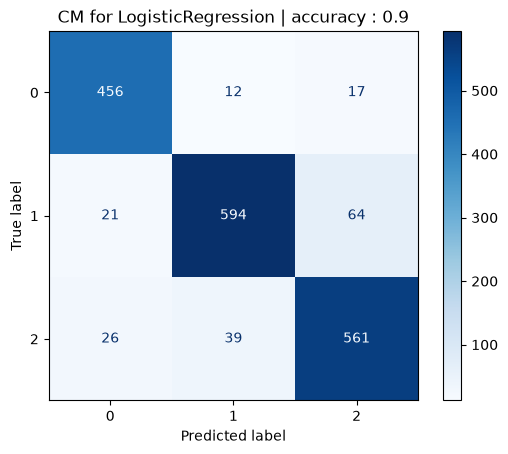

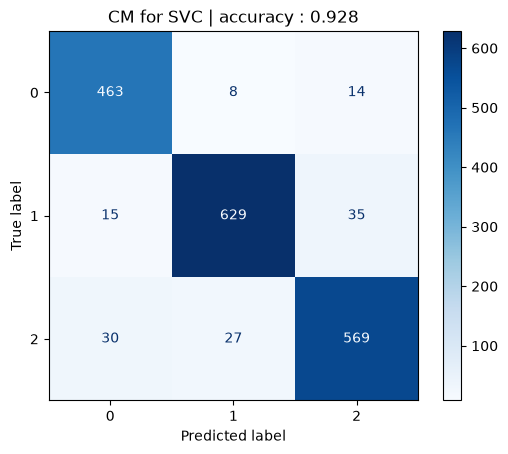

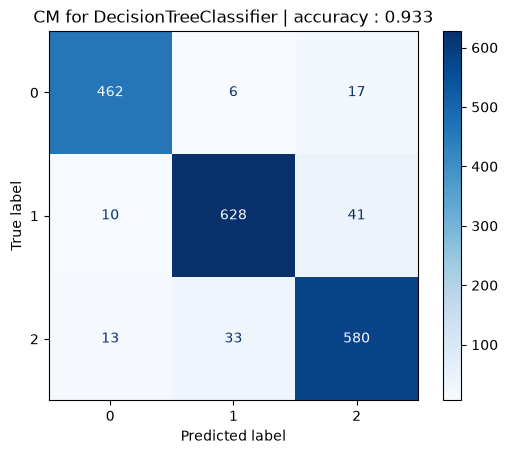

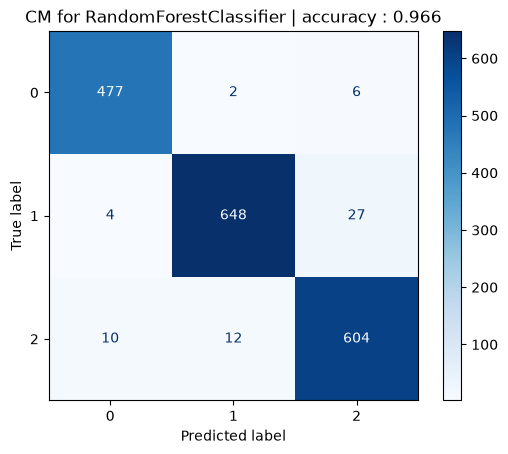

In [37]:
# visualize the confusion matrix of all models : 
for i in range(0 , len(result)) : 
   
    cm = result.iloc[i]['confusion_matrix'] 
    
    disp = ConfusionMatrixDisplay(confusion_matrix=cm , display_labels=["0" , "1", "2"])
    disp.plot(cmap=plt.cm.Blues)
    
    plt.title(f"CM for {result.iloc[i]['model_name']} | accuracy : {result.iloc[i]["accuracy_score"].round(3)}")
    plt.show()





In [38]:
# recall : tp / (tp + fn)

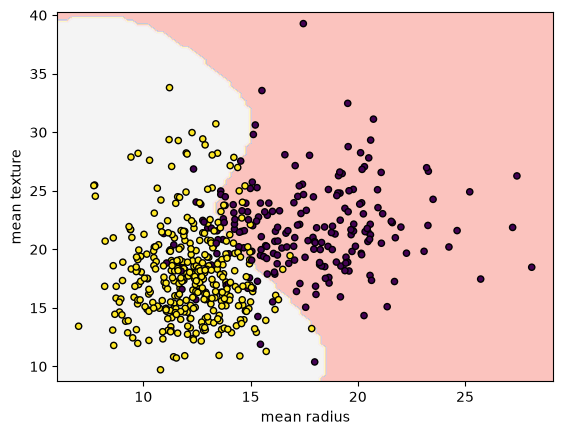

In [39]:
# testing MVC : 
from sklearn.datasets import load_breast_cancer
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.svm import SVC


df = load_breast_cancer()
X = df.data[:, :2]
Y = df.target


svm = SVC()

svm.fit(X, Y)



DecisionBoundaryDisplay.from_estimator(
        svm,
        X,
        response_method="predict",
        alpha=0.8,
        cmap="Pastel1",
        xlabel=df.feature_names[0],
        ylabel=df.feature_names[1],
    )


plt.scatter(X[:, 0], X[:, 1] , c=Y , s=20,  edgecolors="k")

plt.show()

In [51]:
from joblib import dump , load 

model = result.iloc[3]["model"]

dump(model , "best_model.joblib")



['best_model.joblib']

In [53]:

load_model = load("best_model.joblib")


predictions = load_model.predict(x_train)


predictions 


array(['Cash-Advance', 'Cash-Advance', 'Low-Activity', ..., 'High-Value',
       'Low-Activity', 'Cash-Advance'], shape=(7159,), dtype=object)